# Pandas Time Series

Today we are going to look at CO$_2$ data and try to learn about time series.  I will  introduce it and then you will be in charge of analyzing CO$_2$ data from Mauna Lao.  We are going to start by looking at the data from the Scripps Pier.  

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pylab as plt
from scipy import stats

np.set_printoptions(legacy='1.25') #removes the funny printing

# CO2 data
### First go get CO$_2$ data for CO$_2$ we are going to use NOAA.
#### Class will use Barrow Alaska.  Homework will use Mauna Loa
- https://gml.noaa.gov/
- Click Data and Products -> Data Finder
- Click
    - Green House Gases
    - Carbon Dioxide
    - Insitu
    - Daily Averages
    - Then scroll down
- Click Barrow
- Right Click Download Data Text File
- Save it in a folder you can use
- Now double click it from finder and look at it.
- Now we can read it in.  
- Python has a lot of crazy file reading capabilities.
- I used AI to help me make the white space sepeartor

#### How you start with a dataset
- Read in your data
- Look at your data
- Look at columns to make sure names are good
- Look at info


#### Read in

In [75]:
filename = 'co2_brw_surface-insitu_1_ccgg_DailyData.txt'

# 2. Read whitespace-delimited .txt file into Pandas
df = pd.read_csv(
    filename,
    comment='#',  # Ignores all metadata lines starting with '#'
    sep=r'\s+',  # Handles variable spaces between columns
    engine='python',
)

#### Look at

In [28]:
df

,site_code,year,month,day,hour,minute,second,datetime,time_decimal,midpoint_time,value,value_std_dev,nvalue,latitude,longitude,altitude,elevation,intake_height,qcflag
0,BRW,1973,7,24,0,0,0,1973-07-24T00:00:00Z,1973.558904,112363200,-999.99,-99.99,0,71.323,-156.611,1.10,11.0,-9.90,*..
1,BRW,1973,7,25,0,0,0,1973-07-25T00:00:00Z,1973.561644,112449600,-999.99,-99.99,0,71.323,-156.611,1.10,11.0,-9.90,*..
2,BRW,1973,7,26,0,0,0,1973-07-26T00:00:00Z,1973.564384,112536000,-999.99,-99.99,0,71.323,-156.611,1.10,11.0,-9.90,*..
3,BRW,1973,7,27,0,0,0,1973-07-27T00:00:00Z,1973.567123,112622400,325.21,1.65,10,71.323,-156.611,27.00,11.0,16.00,...
4,BRW,1973,7,28,0,0,0,1973-07-28T00:00:00Z,1973.569863,112708800,324.36,0.23,10,71.323,-156.611,27.00,11.0,16.00,...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
19149,BRW,2025,12,27,0,0,0,2025-12-27T00:00:00Z,2025.986301,1766836800,434.99,0.15,12,71.323,-156.611,46.05,11.0,35.05,...
19150,BRW,2025,12,28,0,0,0,2025-12-28T00:00:00Z,2025.989041,1766923200,434.94,0.17,16,71.323,-156.611,46.05,11.0,35.05,...
19151,BRW,2025,12,29,0,0,0,2025-12-29T00:00:00Z,2025.991781,1767009600,434.89,0.39,24,71.323,-156.611,46.05,11.0,35.05,...
19152,BRW,2025,12,30,0,0,0,2025-12-30T00:00:00Z,2025.994521,1767096000,434.53,0.25,24,71.323,-156.611,46.05,11.0,35.05,...


#### Columns
- make sure no leading or trailing spaces
- make sure names look good

In [30]:
df.columns

Index(['site_code', 'year', 'month', 'day', 'hour', 'minute', 'second',
       'datetime', 'time_decimal', 'midpoint_time', 'value', 'value_std_dev',
       'nvalue', 'latitude', 'longitude', 'altitude', 'elevation',
       'intake_height', 'qcflag'],
      dtype='str')

#### info
- make sure things are what they are

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19154 entries, 0 to 19153
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   site_code      19154 non-null  str    
 1   year           19154 non-null  int64  
 2   month          19154 non-null  int64  
 3   day            19154 non-null  int64  
 4   hour           19154 non-null  int64  
 5   minute         19154 non-null  int64  
 6   second         19154 non-null  int64  
 7   datetime       19154 non-null  str    
 8   time_decimal   19154 non-null  float64
 9   midpoint_time  19154 non-null  int64  
 10  value          19154 non-null  float64
 11  value_std_dev  19154 non-null  float64
 12  nvalue         19154 non-null  int64  
 13  latitude       19154 non-null  float64
 14  longitude      19154 non-null  float64
 15  altitude       19154 non-null  float64
 16  elevation      19154 non-null  float64
 17  intake_height  19154 non-null  float64
 18  qcflag         19

#### Time!
- Dates are hard!!!!!
- In this file there is a datetime column.  We are going to tell pandas it is a datetime
- you could also put together your year, month day.
- go back to reading in and we will:
    - Say there is a dateime
    - set it to the index!

In [33]:
filename = 'co2_brw_surface-insitu_1_ccgg_DailyData.txt'

# 2. Read whitespace-delimited .txt file into Pandas
df = pd.read_csv(
    filename,
    comment='#',  # Ignores all metadata lines starting with '#'
    sep=r'\s+',  # Handles variable spaces between columns
    engine='python',
    parse_dates=['datetime'],  # Converts string to datetime object on import
    index_col='datetime',  # Sets it as the index immediately
)

#### Look at info!

##### **DatetimeIndex** 
- you need this!!!!!!
- you need this!!!!!!
- Without a datetime or a datetime index the computer can't tell time.
- This is the most common mistake!

In [34]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 19154 entries, 1973-07-24 00:00:00+00:00 to 2025-12-31 00:00:00+00:00
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   site_code      19154 non-null  str    
 1   year           19154 non-null  int64  
 2   month          19154 non-null  int64  
 3   day            19154 non-null  int64  
 4   hour           19154 non-null  int64  
 5   minute         19154 non-null  int64  
 6   second         19154 non-null  int64  
 7   time_decimal   19154 non-null  float64
 8   midpoint_time  19154 non-null  int64  
 9   value          19154 non-null  float64
 10  value_std_dev  19154 non-null  float64
 11  nvalue         19154 non-null  int64  
 12  latitude       19154 non-null  float64
 13  longitude      19154 non-null  float64
 14  altitude       19154 non-null  float64
 15  elevation      19154 non-null  float64
 16  intake_height  19154 non-null  float64
 17  qcflag        

### Make a plot
- plot index
- value

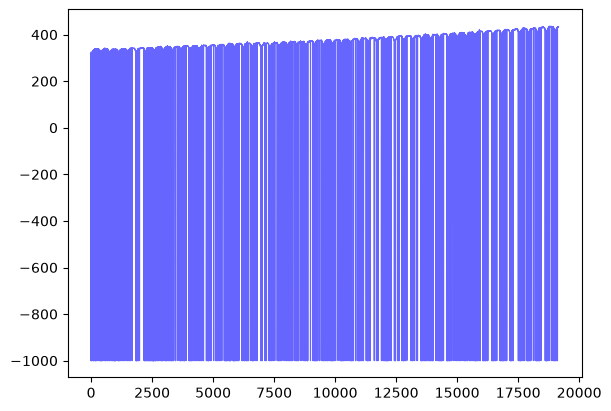

In [76]:
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(
    df.index,
    df['value'],
    color='blue',
    alpha=0.6,
    linewidth=0.8,
)

### What is wrong??????
- The data gives a -999 for missing data.
- We need to make -999.99 and -99.9 missing
- You can replace the numbers with np.nan.  Say they are not a number and missing


In [77]:
df['value'] = df['value'].replace([-999.99, -99.9], np.nan)

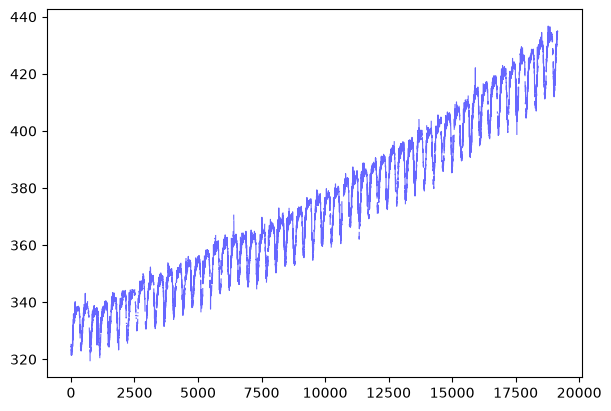

In [78]:
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(
    df.index,
    df['value'],
    color='blue',
    alpha=0.6,
    linewidth=0.8,
)

#### Missing data at readin!

In [79]:
filename = 'co2_brw_surface-insitu_1_ccgg_DailyData.txt'

# 2. Read whitespace-delimited .txt file into Pandas
df = pd.read_csv(
    filename,
    comment='#',  # Ignores all metadata lines starting with '#'
    sep=r'\s+',  # Handles variable spaces between columns
    engine='python',
    parse_dates=['datetime'],  # Converts string to datetime object on import
    index_col='datetime',  # Sets it as the index immediately
    na_values=[-999.99, -99.9],  # Automatically turns these values into np.nan on import
)

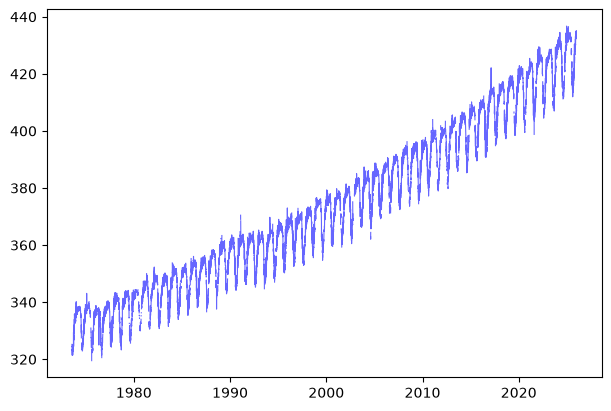

In [80]:
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(
    df.index,
    df['value'],
    color='blue',
    alpha=0.6,
    linewidth=0.8,
)

## That is beautiful.  
- Annual increase
- Seasonal variation!

But there are some outliers

## QC Flag!
- The dataset has a column called qc flag
- The dataset tells you what it means
- If there is not a . in a spot then then the data is bad
- So we need to clean the data!
- look for a non . and then get rid of it.  

In [49]:
baseline_mask = (df['qcflag'].str[0] == '.') & (df['qcflag'].str[1] == '.')
df= df[baseline_mask]

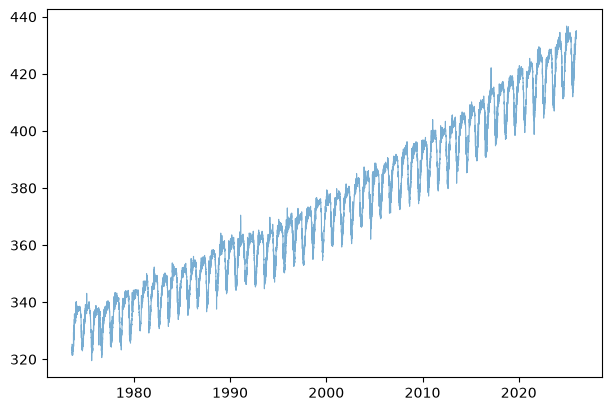

In [67]:
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')

ax.plot(
    df.index,
    df['value'],
    color='tab:blue',
    alpha=0.6,
    linewidth=0.8,
)

### Now we can use Pandas!
- You can select a year and plot it!
- Use loc
- for fun I did a range of hex colors from here https://www.w3schools.com/colors/colors_picker.asp

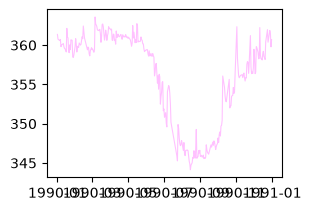

In [69]:
fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

ax.plot(
    df.loc['1990'].index,
    df.loc['1990']['value'],
    color='#ff99ff',
    alpha=0.6,
    linewidth=0.8,
)


#### Plot a range of years!

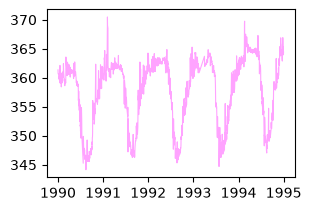

In [68]:
fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

ax.plot(
    df.loc['1990':'1994'].index,
    df.loc['1990':'1994']['value'],
    color='#ff66ff',
    alpha=0.6,
    linewidth=0.8,
)

### Choose dates

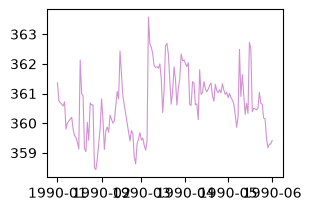

In [70]:
fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

ax.plot(
    df.loc['01/01/1990':'06/01/1990'].index,
    df.loc['01/01/1990':'06/01/1990']['value'],
    color='#b649b6',
    alpha=0.6,
    linewidth=0.8,
)

### Side note

Just for reference

This is a fun trick.  We can use python to grab the csv file for us off of the website!  This is great because you always get the most up to date file.  Do not type the url.  Go right click on the file and say copy link and paste in.  


In [128]:
filename='https://gml.noaa.gov/aftp/data/trace_gases/co2/in-situ/surface/txt/co2_brw_surface-insitu_1_ccgg_DailyData.txt'

#Read whitespace-delimited .txt file into Pandas
df = pd.read_csv(
    filename,
    comment='#',  # Ignores all metadata lines starting with '#'
    sep=r'\s+',  # Handles variable spaces between columns
    engine='python',
    parse_dates=['datetime'],  # Converts string to datetime object on import
    index_col='datetime',  # Sets it as the index immediately
    na_values=[-999.99, -99.9],  # Automatically turns these values into np.nan on import
)

baseline_mask = (df['qcflag'].str[0] == '.') & (df['qcflag'].str[1] == '.')
df= df[baseline_mask]

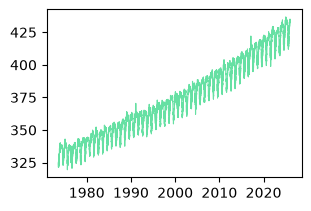

In [129]:
fig, ax = plt.subplots(figsize=(3, 2), layout='constrained')

ax.plot(
    df.index,
    df['value'],
    color='#00cc66',
    alpha=0.6,
    linewidth=0.8,
)

## But first this is an important note.  
-  To make a new column you have to use the [] notation and not the . notation.  
-  Say you wanted to do math.  e.g CO2*10


In [85]:
df['10xCO2']=df['value']*10.

### You could also set it to a new dataframe

In [98]:
dfClean=pd.DataFrame()
dfClean['decade']=df['value']*10.

## RESAMPLING
- Resampling lets you average your data over a different time span
- Get a weekly, yearly, monthly average etc.
- It can do a lot.
- We can convert to an annual average CO2


In [95]:
df['value'].resample('YE').mean()

datetime
1973-12-31 00:00:00+00:00    329.201538
1974-12-31 00:00:00+00:00    333.790102
1975-12-31 00:00:00+00:00    333.427612
1976-12-31 00:00:00+00:00    333.001241
1977-12-31 00:00:00+00:00    334.952529
1978-12-31 00:00:00+00:00    337.129127
1979-12-31 00:00:00+00:00    338.479670
1980-12-31 00:00:00+00:00    340.509609
1981-12-31 00:00:00+00:00    342.358899
1982-12-31 00:00:00+00:00    343.368478
1983-12-31 00:00:00+00:00    344.382500
1984-12-31 00:00:00+00:00    346.523673
1985-12-31 00:00:00+00:00    347.271884
1986-12-31 00:00:00+00:00    349.389419
1987-12-31 00:00:00+00:00    350.245519
1988-12-31 00:00:00+00:00    353.409659
1989-12-31 00:00:00+00:00    355.317163
1990-12-31 00:00:00+00:00    356.134571
1991-12-31 00:00:00+00:00    357.946656
1992-12-31 00:00:00+00:00    357.974050
1993-12-31 00:00:00+00:00    357.624548
1994-12-31 00:00:00+00:00    360.536844
1995-12-31 00:00:00+00:00    362.597557
1996-12-31 00:00:00+00:00    364.434561
1997-12-31 00:00:00+00:00    36

## Linear Regression
- Linear regression of CO2 over time
- x will be a resmapled average time
- y will be a resampled average CO2
- Go grab your best linar regression cell and put it together! 
- But This is weird and we need to think some.

### How do we make a nice annually averaged dataframe to analyze?
1. resample and get annual values in a new dataframe
2. Now you have two choices
    1. First You can make a new column in your dataframe that is the date then you can use the dfClean method
    2. Second you export the x and y values you pass x and y.
3. They both work.  Let's look at the two


### Method 1 Making a new dataframe (Harder)

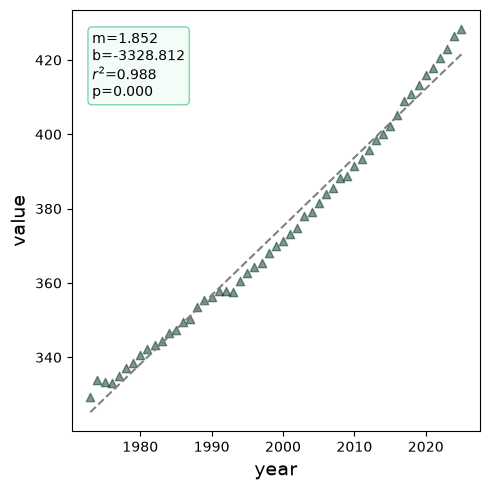

In [113]:
df_Annual=pd.DataFrame()

df_Annual['value']=df['value'].resample('YE').mean()   # Getting the annual average
df_Annual['year']=df_Annual.index.year                 # pulling out the year

Xcolumn='year'
Ycolumn='value'
dfClean=df_Annual[[Xcolumn,Ycolumn]].dropna()   #dropna defaults to any missing data it drops that row

# 2. Text box properties
props=dict(boxstyle='round'
           ,facecolor='#eafbf2'
           ,edgecolor='#00b259'
           ,alpha=0.5
)  #properties of the text box

# turn on plot
fig,ax=plt.subplots(layout='tight',figsize=(5,5))

# Scatter plot
ax.scatter(dfClean[Xcolumn]
           ,dfClean[Ycolumn]
           ,alpha=0.5
           ,color='#00331a'
          ,marker=r'^'
          ,label='Data')

# Regression
LinResult =stats.linregress(dfClean[Xcolumn],dfClean[Ycolumn])
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(dfClean[Xcolumn].min(), dfClean[Xcolumn].max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax.set_xlabel(Xcolumn,fontsize=14)
ax.set_ylabel(Ycolumn,fontsize=14)

ax.text(0.05,0.95, textstr, transform=ax.transAxes
        ,fontsize=10 ,va='top',ha='left' ,bbox=props)     #add the text box

plt.show()


### Method 2 Setting an X and Y (Easier)


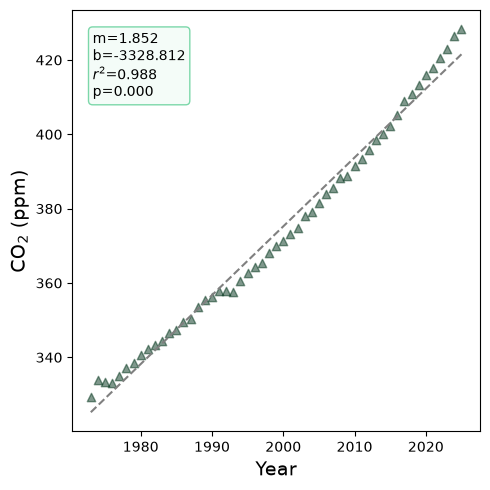

In [186]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='CO$_2$ (ppm)'

# 2. Text box properties
props=dict(boxstyle='round'
           ,facecolor='#eafbf2'
           ,edgecolor='#00b259'
           ,alpha=0.5
)  #properties of the text box

# turn on plot
fig,ax=plt.subplots(layout='tight',figsize=(5,5))

# Scatter plot
ax.scatter(x
           ,y
           ,alpha=0.5
           ,color='#00331a'
          ,marker=r'^'
          ,label='Data')

# Regression
LinResult =stats.linregress(x,y)
textstr= (
    f'm={LinResult.slope:.3f}\n'
    f'b={LinResult.intercept:.3f}\n'
    f'$r^2$={LinResult.rvalue**2:.3f}\n'
    f'p={LinResult.pvalue:.3f}'
)

## Best fit line
x_fit = np.linspace(x.min(), x.max())   #make the x values
y_fit = x_fit*LinResult.slope + LinResult.intercept

ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')

# Label Plot
ax.set_xlabel(xLabel,fontsize=14)
ax.set_ylabel(yLabel,fontsize=14)

ax.text(0.05,0.95, textstr, transform=ax.transAxes
        ,fontsize=10 ,va='top',ha='left' ,bbox=props)     #add the text box

plt.show()



## Good or Bad Fit?
the $r^2$ is great but the curve looks non-linear. You can try to look at the graph "down the line" and you will see the line is straight but the points curve around it.  Twist your computer to look down the line
- So the error looks systematic and not random.  could we find the residuals and plot them?  
- So could we plot how far off the value is from the line for each year?  
- So the residual is the difference in y-space for each value for each year. residuals=observed-predicted.  I would make the residual by doing the math to look at the difference.

* Residual is Observed minus expected (observed-expected)
* expected=m*x+b from linregess
* so your resdiual beomces y-(mx+b)
* plot the residual versus x
* add the horizontal line by using ax.axhline(y=0)
* think about the data...

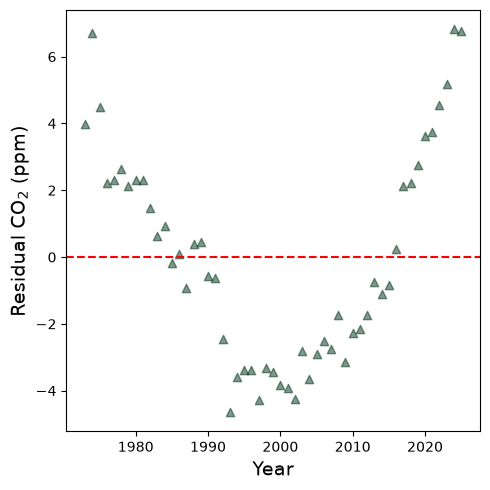

In [188]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='Residual CO$_2$ (ppm)'


# turn on plot
fig,ax=plt.subplots(layout='tight',figsize=(5,5))

# Regression
LinResult =stats.linregress(x,y)

#ax.plot(x_fit,y_fit,label='Fit',color='gray',linestyle='--')
ax.scatter(x
           ,y-(x*LinResult.slope + LinResult.intercept)
           ,alpha=0.5
           ,color='#00331a'
          ,marker=r'^'
          ,label='Data')

# Horizontal Line at 0
ax.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5
)

# Label Plot
ax.set_xlabel(xLabel,fontsize=14)
ax.set_ylabel(yLabel,fontsize=14)


plt.show()


# What does a curved line mean?
### Good or bad news?

## AI Practice
- Can we make an AI call to show the fit and residuals on two seperate plots?
- First find your versions

In [124]:
import matplotlib
import platform
import sys

# Detect macOS reliably across all Mac models
os_name = "macOS" if sys.platform == "darwin" else platform.system()

# Safely check JupyterLab version if installed in the current kernel
try:
  import jupyterlab

  jl_ver = jupyterlab.__version__
except ImportError:
  jl_ver = "4.x"  # Fallback estimate

prompt_text = (
    f"I am running Python {sys.version.split()[0]} with Matplotlib "
    f"{matplotlib.__version__} in JupyterLab {jl_ver} on {os_name}. "
    f"Please write code compatible with these versions."
)

print(prompt_text)

I am running Python 3.11.15 with Matplotlib 3.11.1 in JupyterLab 4.6.3 on macOS. Please write code compatible with these versions.


## Make an AI prompt

"Write a complete Python script using `pandas` and `matplotlib` to create a high-resolution, publication-quality diagram in a single Jupyter notebook cell.   Use fig,ax=plt.subplots()

I am running Python 3.11.15 with Matplotlib 3.11.1 in JupyterLab 4.6.3 on macOS. Please write code compatible with these versions.

Make a plot that shows a linear fit of the annually averaged CO2 data from Barrow Alaska along with the residuals on two seperate plots
- Use the file 'co2_brw_surface-insitu_1_ccgg_DailyData.txt' and set the index to datetime
- The CO2 data is called value and the date is called dateitme
- make sure to remove all missing data and any samples with an issue with a qcflag
- align the plots vertically
- make all fontsizes adjustable
- make sure all axes are nicely labeled
- save to a unique filename
- use resample to determine annual averages of CO2 for the linear fit
- Show the results of the linear regression in a text box on the graph
- for the residuals add a horizontal line at 0
- summarize the data and how the linear regression fits the data
- make recommendations if any other types of fits should be used for the data.
- make recommendations for ways to improve the instructions for AI. 

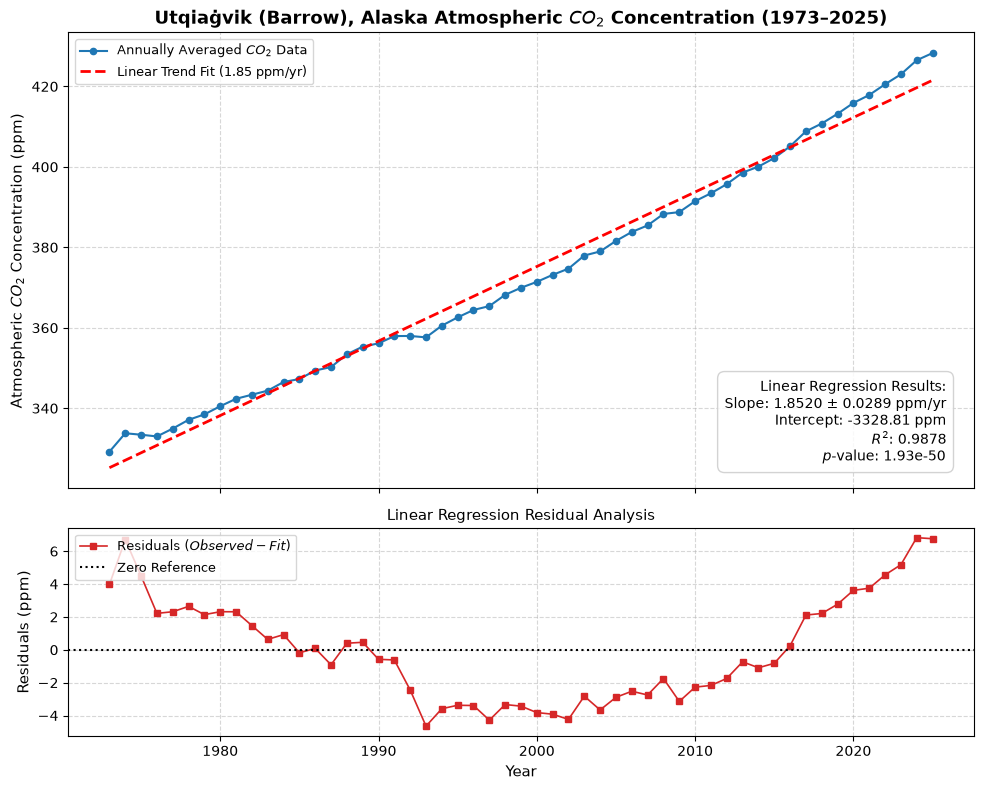

Diagram successfully saved to: barrow_co2_linear_fit_residuals_20261101_172520.png


In [122]:
import datetime
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import linregress

# --- Adjustable Font & Visual Parameters ---
FONT_SIZE_TITLE = 13
FONT_SIZE_LABEL = 11
FONT_SIZE_TICK = 10
FONT_SIZE_TEXT = 9.5
FONT_SIZE_LEGEND = 9.5
FIGURE_DPI = 300

plt.rcParams.update({
    'font.size': FONT_SIZE_TICK,
    'axes.labelsize': FONT_SIZE_LABEL,
    'axes.titlesize': FONT_SIZE_TITLE,
    'xtick.labelsize': FONT_SIZE_TICK,
    'ytick.labelsize': FONT_SIZE_TICK,
    'legend.fontsize': FONT_SIZE_LEGEND,
})

# --- 1. Load Data and Filter Quality Flags ---
filename = 'co2_brw_surface-insitu_1_ccgg_DailyData.txt'

# Read space-delimited file, ignoring NOAA metadata lines beginning with '#'
df = pd.read_csv(filename, comment='#', sep=r'\s+')

# Filter out missing measurements (value <= 0 or -999.99) and QC flag anomalies
# '...' indicates a fully valid background sample meeting NOAA selection criteria
df_clean = df[(df['value'] > 0) & (df['qcflag'] == '...')].copy()

# Convert datetime string to pandas DatetimeIndex
df_clean['datetime'] = pd.to_datetime(df_clean['datetime'])
df_clean.set_index('datetime', inplace=True)

# --- 2. Calculate Annual Averages & Linear Fit ---
# Resample clean daily observations to annual start ('YS') averages
annual_co2 = df_clean['value'].resample('YS').mean().dropna()

x_years = annual_co2.index.year.values
y_co2 = annual_co2.values

# Perform Ordinary Least Squares (OLS) Linear Regression
slope, intercept, r_value, p_value, std_err = linregress(x_years, y_co2)
r_squared = r_value**2
y_fit = slope * x_years + intercept
residuals = y_co2 - y_fit

# --- 3. Vertically Aligned Subplots Construction ---
fig, ax = plt.subplots(
    2, 1, figsize=(10, 8), sharex=True, gridspec_kw={'height_ratios': [2.2, 1]}
)

# Upper Panel: Main Data and Linear Regression Line
ax[0].plot(
    annual_co2.index,
    y_co2,
    'o-',
    color='#1f77b4',
    linewidth=1.5,
    markersize=4.5,
    label='Annually Averaged $CO_2$ Data',
)
ax[0].plot(
    annual_co2.index,
    y_fit,
    'r--',
    linewidth=2,
    label=f'Linear Trend Fit ({slope:.2f} ppm/yr)',
)
ax[0].set_ylabel('Atmospheric $CO_2$ Concentration (ppm)')
ax[0].set_title(
    'Utqiaġvik (Barrow), Alaska Atmospheric $CO_2$ Concentration (1973–2025)',
    fontweight='bold',
)
ax[0].grid(True, linestyle='--', alpha=0.5)
ax[0].legend(loc='upper left', frameon=True)

# Annotated Regression Statistics Text Box
stats_box = (
    f"Linear Regression Results:\n"
    f"Slope: {slope:.4f} ± {std_err:.4f} ppm/yr\n"
    f"Intercept: {intercept:.2f} ppm\n"
    f"$R^2$: {r_squared:.4f}\n"
    f"$p$-value: {p_value:.2e}"
)
ax[0].text(
    0.97,
    0.05,
    stats_box,
    transform=ax[0].transAxes,
    verticalalignment='bottom',
    horizontalalignment='right',
    bbox=dict(boxstyle='round,pad=0.5', facecolor='white', alpha=0.85, edgecolor='#cccccc'),
)

# Lower Panel: Linear Regression Residuals
ax[1].plot(
    annual_co2.index,
    residuals,
    's-',
    color='#d62728',
    linewidth=1.2,
    markersize=4,
    label='Residuals ($Observed - Fit$)',
)
ax[1].axhline(0, color='black', linestyle=':', linewidth=1.5, label='Zero Reference')
ax[1].set_xlabel('Year')
ax[1].set_ylabel('Residuals (ppm)')
ax[1].set_title('Linear Regression Residual Analysis', fontsize=FONT_SIZE_LABEL)
ax[1].grid(True, linestyle='--', alpha=0.5)
ax[1].legend(loc='upper left', frameon=True)

plt.tight_layout()

# Save High-Resolution Output File
timestamp = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
output_filename = f'barrow_co2_linear_fit_residuals_{timestamp}.png'
plt.savefig(output_filename, dpi=FIGURE_DPI, bbox_inches='tight')
plt.show()

print(f'Diagram successfully saved to: {output_filename}')

# Non Linear fit
- So linear ain't working!  
- We can use poly1d to fit a polynominal!
- So lets figure out how to use poly1d and see how a second order equation fits the data!  poly1d has lots of cool tricks!

Remember for a polynominal
- 1st order  y=ax+b
- 2nd order y=ax$^2$+bx+c
- 3rd order y=ax$^3$+bx$^2$+cx+d
etc...

How it works.  Like linregress.  You pass your x,y and now the order to poly1d
- set 
    - fit_order to 2 for a second order polynominal
    - fit_order=2
- Now use polyfit
    - coeffs=np.polyfit(x,y,fit_order)
    - coeffs is now an array where coeffs[0]=a, coeffs[1]=b, ....
- Now it gets cool.
    - coeffs is now a python class.
    - You can pass that to np.poly1d(coeffs)
    - polynominal=np.poly1d(coeffs)
- It returns the equation.  I called it polynomial.  But that equation will also do math for you.  You give it an X and it gives you Y! So used linspace to make a bunch of x values!  You want more than 2 now becuase your line will be curved.
- x_fit=np.linspace(x.min(),x.max())  
- Now send your x_fit into polynominal and you have all your y's!
     - y_fit=polynominal(x_fit)



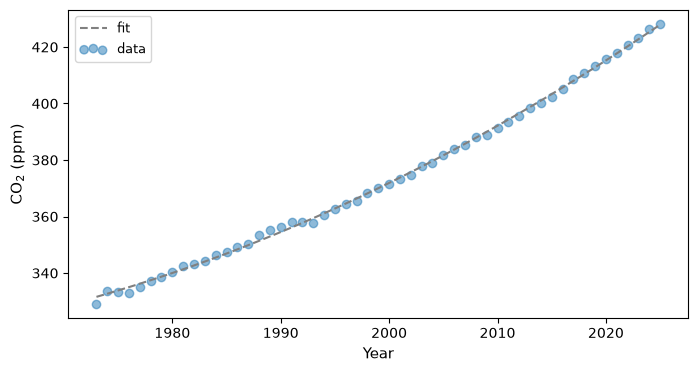

In [172]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='CO2 ppm'

fig,ax=plt.subplots(figsize=(8,4))

#polyfit
fit_order=2
x_fit=np.linspace(x.min(),x.max())  #I set the range using the data
coeffs=np.polyfit(x,y,fit_order)  #I just copied from above to have in the same cell
polynominal=np.poly1d(coeffs)
y_fit=polynominal(x_fit)

# plotting
ax.plot(x_fit,y_fit,color='grey',ls='--',label='fit')
ax.scatter(x,y,alpha=0.5,label='data')

# making it look good
ax.set_ylabel('CO$_2$ (ppm)')
ax.set_xlabel('Year')
ax.legend(scatterpoints=3)
plt.show()

## Great Fit!

I know that was all just weird.  But that is python and object oriented code.  It can do work for you.

#### Now let's add the equation and the r2
* We will use f formatting for the equation
* coeffs is an array that is the a,b,c coefficents
    * we can say a,b,c = coeff
    * or you can do coeff[0],coeff[1],coeff[2]
* So we can use Latex and write CO$_2$=...
* Then we can calculate an r2
    * r2 = np.corrcoef(y, polynominal(x))[0, 1] ** 2
    * you are just getting the correlation between the value and the predicted.  A little simpler than using linregress
* Add the text box and we are professional!


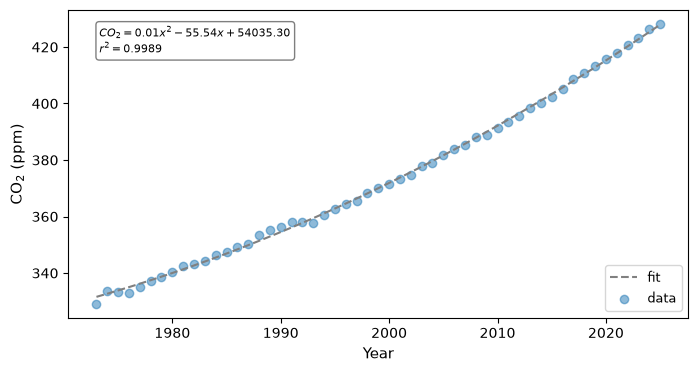

In [167]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='CO2 ppm'

props=dict(boxstyle='round',facecolor='white',alpha=0.5)

fig,ax=plt.subplots(figsize=(8,4))

# polyfit
fit_order=2
x_fit=np.linspace(x.min(),x.max())  #I set the range using the data
coeffs=np.polyfit(x,y,fit_order)  #I just copied from above to have in the same cell
polynominal=np.poly1d(coeffs)
y_fit=polynominal(x_fit)

# To get r2 calculate between y and the predictedd y
r2 = np.corrcoef(y, polynominal(x))[0, 1] ** 2


#make the text box
a,b,c=coeffs
textstr=(
    f'$CO_2={a:.2f}x^2{b:+.2f}x{c:+.2f}$\n'
    f'$r^2={r2:.4f}$'
)
ax.text(0.05,0.95,textstr,transform=ax.transAxes,fontsize=8
        ,verticalalignment='top',bbox=props)

# plot the data
ax.plot(x_fit,y_fit,color='grey',ls='--',label='fit')
ax.scatter(x,y,alpha=0.5,label='data')

#make it look good
ax.set_ylabel('CO$_2$ (ppm)')
ax.set_xlabel('Year')
ax.legend()
plt.show()

### Residuals

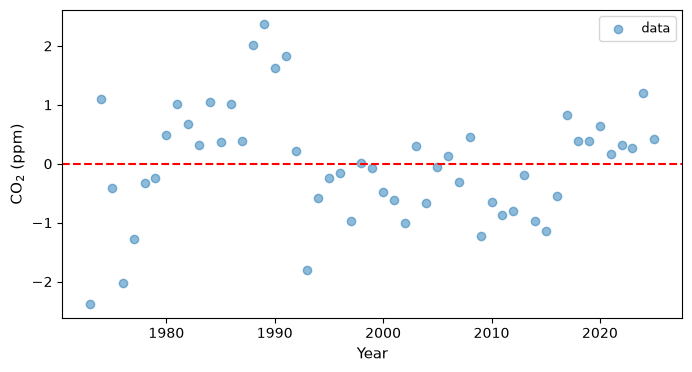

In [169]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='CO2 ppm'

props=dict(boxstyle='round',facecolor='white',alpha=0.5)

fig,ax=plt.subplots(figsize=(8,4))

## Polyfit
fit_order=2
x_fit=np.linspace(x.min(),x.max())  #I set the range using the data
coeffs=np.polyfit(x,y,fit_order)  #I just copied from above to have in the same cell
polynominal=np.poly1d(coeffs)
y_fit=polynominal(x_fit)

ax.scatter(x,y-polynominal(x),alpha=0.5,label='data')

# Horizontal Line at 0
ax.axhline(
    y=0,
    color='red',
    linestyle='--',
    linewidth=1.5
)

ax.set_ylabel('CO$_2$ (ppm)')
ax.set_xlabel('Year')
ax.legend()
plt.show()

## Predictions
Now make a prediction for CO2 for 2050!  Can you extend the line to 2050?

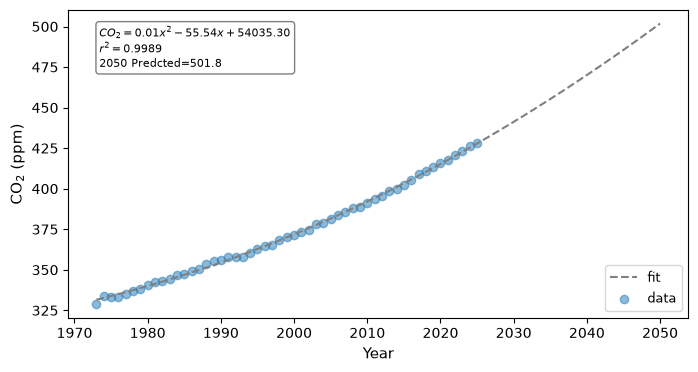

In [178]:
y=df['value'].resample('YE').mean()   # Getting the annual average
x=y.index.year                 # pulling out the year

xLabel='Year'
yLabel='CO2 ppm'

props=dict(boxstyle='round',facecolor='white',alpha=0.5)

fig,ax=plt.subplots(figsize=(8,4))

# polyfit
fit_order=2
x_fit=np.linspace(x.min(),2050)  #I set the range using the data
coeffs=np.polyfit(x,y,fit_order)  #I just copied from above to have in the same cell
polynominal=np.poly1d(coeffs)
y_fit=polynominal(x_fit)

# To get r2 calculate between y and the predictedd y
r2 = np.corrcoef(y, polynominal(x))[0, 1] ** 2

a,b,c=coeffs
textstr=(
    f'$CO_2={a:.2f}x^2{b:+.2f}x{c:+.2f}$\n'
    f'$r^2={r2:.4f}$\n'
    f'2050 Predcted={polynominal(2050):.1f}'
)
ax.text(0.05,0.95,textstr,transform=ax.transAxes,fontsize=8
        ,verticalalignment='top',bbox=props)

ax.plot(x_fit,y_fit,color='grey',ls='--',label='fit')
ax.scatter(x,y,alpha=0.5,label='data')

ax.set_ylabel('CO$_2$ (ppm)')
ax.set_xlabel('Year')
ax.legend()
plt.show()



# CO$_2$ Box Model

We are going to make a box model to try and explain CO2 concentrations.  

I am freely taking from this website
http://serc.carleton.edu/quantskills/activities/co2_global.html
and this website. http://serc.carleton.edu/quantskills/activities/co2_global.html
Robert Mackay is the person behind this. 

We are going to treat the atmosphere as a simple box model.  Here is a figure describing it.  It is simple.  Think about that we are adding CO2,  it is building up in the atmosphere, and then it is leaving.  The rate we are adding is increasing but it is leaving at a constant rate.  

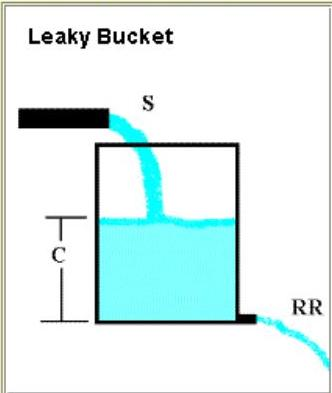

# this makes the equation
# $\frac{dC}{dt}=S-\frac{C}{\tau}$

# Which when solved becomes: 

# $C(t)=C_oe^{-t/\tau}+\frac{S_o}{R+\frac{1}{\tau}}\big[e^{Rt}-e^{-t/\tau}  \big]$

## Here are the definitions and typical units for each parameter:
####  $C$ or $C(t)$: 
* Atmospheric $CO_2$ amount or concentration at time $t$.Units: $\text{ppm}$ (parts per million) or $\text{GtC}$ (Gigatons of Carbon, where $1\text{ ppm} \approx 2.12\text{ GtC}$).
#### * $t$: 
* Elapsed time from the baseline starting point ($t = 0$).Units: Years ($\text{yr}$).
#### * $C_0$: 
* Initial $CO_2$ concentration at $t = 0$.Units: $\text{ppm}$ or $\text{GtC}$.
#### * $\tau$ (Tau): 
* Effective atmospheric residence time (or e-folding relaxation timescale) of $CO_2$ against natural removal sinks (ocean + terrestrial biosphere).Units: Years ($\text{yr}$).  We will use 120 years
#### * $S(t)$: 
* Net total emission rate of $CO_2$ into the atmosphere at time $t$.Units: $\text{ppm/yr}$ or $\text{GtC/yr}$.
#### * $S_0$: 
* Initial $CO_2$ emission rate at $t = 0$.Units: $\text{ppm/yr}$ or $\text{GtC/yr}$.
#### * $R$: 
* Fractional annual growth rate of emissions.Units: $\text{yr}^{-1}$ (e.g., $R = 0.02$ corresponds to a $2\%$ annual increase in emissions).



### Reload the data to start clean

In [179]:
filename='https://gml.noaa.gov/aftp/data/trace_gases/co2/in-situ/surface/txt/co2_brw_surface-insitu_1_ccgg_DailyData.txt'

#Read whitespace-delimited .txt file into Pandas
df = pd.read_csv(
    filename,
    comment='#',  # Ignores all metadata lines starting with '#'
    sep=r'\s+',  # Handles variable spaces between columns
    engine='python',
    parse_dates=['datetime'],  # Converts string to datetime object on import
    index_col='datetime',  # Sets it as the index immediately
    na_values=[-999.99, -99.9],  # Automatically turns these values into np.nan on import
)

baseline_mask = (df['qcflag'].str[0] == '.') & (df['qcflag'].str[1] == '.')
df= df[baseline_mask]

### Elapsed Time
* to make this work you will need elapsed time.
* This is a little tricky to make and takes a few tricks.  lets run through them.
  
#### First you need a start time which is the first index.  
* But since it is an index you need to use index to get the time.
* Elapsed becomes the value minus the first value

In [180]:
df['elapsed'] = df.index - df.index[0]

In [182]:
print(df['elapsed'])

datetime
1973-07-27 00:00:00+00:00       0 days
1973-07-28 00:00:00+00:00       1 days
1973-07-29 00:00:00+00:00       2 days
1973-07-30 00:00:00+00:00       3 days
1973-07-31 00:00:00+00:00       4 days
                               ...    
2025-12-27 00:00:00+00:00   19146 days
2025-12-28 00:00:00+00:00   19147 days
2025-12-29 00:00:00+00:00   19148 days
2025-12-30 00:00:00+00:00   19149 days
2025-12-31 00:00:00+00:00   19150 days
Name: elapsed, Length: 17141, dtype: timedelta64[us]


## UNITS!
* elapsed time has units of days and it is caleed a timedelta64[us]
* This means we can't do math on it unless we use datetime functions.
* We are goign to convert to years
* And if we divide by 365 days.25 it will put it into years.

In [183]:
df['elapsed'] = (df.index - df.index[0])\
                    /pd.Timedelta(days=365.25)

In [184]:
print(df['elapsed'])

datetime
1973-07-27 00:00:00+00:00     0.000000
1973-07-28 00:00:00+00:00     0.002738
1973-07-29 00:00:00+00:00     0.005476
1973-07-30 00:00:00+00:00     0.008214
1973-07-31 00:00:00+00:00     0.010951
                               ...    
2025-12-27 00:00:00+00:00    52.418891
2025-12-28 00:00:00+00:00    52.421629
2025-12-29 00:00:00+00:00    52.424367
2025-12-30 00:00:00+00:00    52.427105
2025-12-31 00:00:00+00:00    52.429843
Name: elapsed, Length: 17141, dtype: float64


# I am going to show you how to do the first term and then you are on your own!
* set Co.  You can average the first year
* remember to do e to the something use np.exp()
  

In [17]:
Co=df.loc['1973']['value'].mean()

329.2015384615385

In [18]:
Co=df.loc['1973']['value'].mean()
tau=120

term1=Co*np.exp(-1*df['elapsed']/tau)



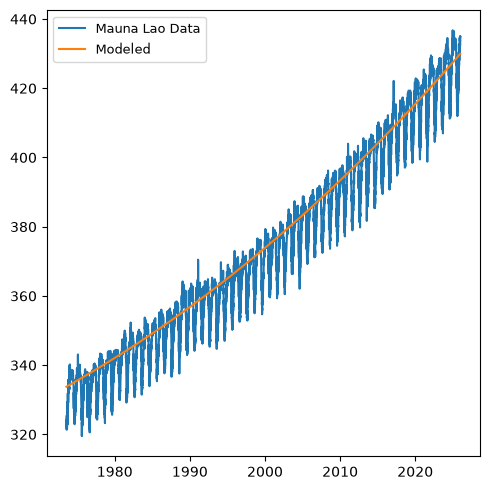

### new page
<div style="page-break-before: always;"></div>


# Exit Ticket
## Name:
## uni:

### Q1. In 1-3 sentences describe what causes the seasonal variations in CO2.  


<div style="page-break-before: always;"></div>
### Ignore.  For printing to pdf.  

In [190]:
%%html
<style>
@media print {
    body {
        zoom: 0.70; /* Scales everything down to 80% of original size */
    }
}
</style>

In [191]:
import ipynbname
from pypdf import PdfReader, PdfWriter

# Dynamically fetch the current notebook's name (without the .ipynb extension)
filename = ipynbname.name()

# Convert to PDF
!uv run jupyter nbconvert --to webpdf {filename}.ipynb \
    --log-level=CRITICAL \
    --WebPDFExporter.display_header_footer=True \
    --WebPDFExporter.header_template='<span></span>' \
    --WebPDFExporter.footer_template='<div style="font-size: 9pt; font-family: sans-serif; width: 100%; text-align: right; padding-right: 0.5in;"><span class="pageNumber"></span> of <span class="totalPages"></span></div>'

# Strip the last page
reader = PdfReader(f"{filename}.pdf")
writer = PdfWriter()
for page in reader.pages[:-1]:
    writer.add_page(page)
writer.write(f"{filename}.pdf")

(True, <_io.FileIO [closed]>)

In [192]:
from io import BytesIO
import time
import ipynbname
from ipylab import JupyterFrontEnd
from pypdf import PdfReader, PdfWriter
from reportlab.pdfgen import canvas

# 1. Force JupyterLab to save latest changes
app = JupyterFrontEnd()
app.commands.execute("docmanager:save")
time.sleep(1)

# 2. Get current notebook name
filename = ipynbname.name()

# 3. Convert notebook to PDF
!uv run jupyter nbconvert --to webpdf "{filename}.ipynb" --log-level=CRITICAL

# 4. Read PDF and isolate non-setup pages
reader = PdfReader(f"{filename}.pdf")
valid_pages = reader.pages[:-2]  # Strip final page
total_pages = len(valid_pages)


# Helper function to generate page number overlay
def create_footer_overlay(page_num, total, width, height):
  packet = BytesIO()
  c = canvas.Canvas(packet, pagesize=(width, height))
  c.setFont("Helvetica", 9)
  c.setFillColorRGB(0.3, 0.3, 0.3)  # Muted grey text

  # Stamp 0.5 inches (36pt) from bottom-right corner
  c.drawRightString(width - 36, 36, f"Page {page_num} of {total}")
  c.save()
  packet.seek(0)
  return PdfReader(packet).pages[0]


# 5. Stamp numbers and build final PDF
writer = PdfWriter()
for idx, page in enumerate(valid_pages, start=1):
  w = float(page.mediabox.width)
  h = float(page.mediabox.height)

  # Stamp page number onto the current page
  overlay = create_footer_overlay(idx, total_pages, w, h)
  page.merge_page(overlay)
  writer.add_page(page)

writer.write(f"{filename}.pdf")
print(
    f"Successfully generated {filename}.pdf ({total_pages} pages with page numbers)."
)

Successfully generated TimeSeries2026.pdf (24 pages with page numbers).
